# Phase 3B Step 3 — Confidence Interval Analysis and Bootstrap Estimation

## Customer Retention Intelligence System

This independent notebook estimates uncertainty for selected development-split statistics.
It implements analytical confidence intervals, subgroup intervals, Welch and Newcombe
differences, nonparametric bootstrap intervals, and synthetic repeated-sampling coverage.

**Scope and safeguards.** Only the configured `development.parquet` is loaded. Telecom
results are exploratory, generally unadjusted for multiple comparisons, and conditional on
an assumed sampling framework. The IBM file's sampling mechanism is unknown, so the
intervals do not independently establish population representativeness, confirm hypotheses,
or support causal claims. There are no telecom p-values, formal feature selection,
production preprocessing, balancing, predictive models, or held-out-data access.

## 1. Independent setup and leakage-safe loading

The project root is discovered from marker files, configuration is loaded through the
project utility, and the configured relative path is asserted before reading. The random
seed and original split are preserved. Prior notebooks are neither imported nor executed.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import math
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
minimum_group_size = int(config["eda"]["minimum_segment_sample_size"])
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
analysis_df = df.copy()
analysis_df["_churned"] = analysis_df[target_column].eq("Yes")
rng = np.random.default_rng(random_state)

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
assert df[["tenure", "MonthlyCharges", "TotalCharges", target_column]].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Configured random state: {random_state}")
print(f"Exploratory minimum subgroup size: {minimum_group_size}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Configured random state: 42
Exploratory minimum subgroup size: 30
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100000,"5,475.900000",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350000,212.300000,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450000,137.100000,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750000,"2,453.300000",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000000,"1,164.050000",No


## 2. Confidence-interval fundamentals

A **point estimate** is one statistic, such as $ar{x}$ or $hat p$. An **interval
estimate** adds a range of values compatible with an assumed sampling model. For a
symmetric interval,

$$\text{estimate}\ \pm\ \underbrace{c_{1-\alpha/2}}_{\text{critical value}}
\underbrace{SE(\widehat\theta)}_{\text{standard error}},$$

where the product is the **margin of error**, $1-\alpha$ is the **confidence level**, and
the upper minus lower endpoint is the **interval width**. Standard error quantifies
sampling uncertainty of an estimator, not customer-to-customer variability. Under regular
IID conditions $SE(\bar X)=s/\sqrt n$, so precision improves at the square-root rate:
quadrupling $n$ roughly halves width. Raising confidence raises the critical value and
widens the interval.

**Correct frequentist interpretation.** If the sampling and interval-construction
procedure were repeated indefinitely, about 95% of the intervals from a valid nominal 95%
procedure would cover the fixed population parameter. After one interval is computed, the
parameter is fixed and that realized interval either covers it or does not; it is incorrect
to assign the parameter a 95% probability of lying in that already calculated interval.

A **prediction interval** concerns a future observation and includes outcome variability,
so it is usually wider than a confidence interval for a mean. A **Bayesian credible
interval** assigns posterior probability to a parameter conditional on a likelihood and
prior; that probability statement is not the frequentist repeated-sampling statement.

All telecom intervals below assume observations behave like independent draws from a stable
data-generating process. The unknown source sampling mechanism, dependence, time drift,
measurement issues, selection bias, and EDA-driven multiplicity can invalidate or limit
that interpretation. Larger samples reduce random error but do not repair bias.

## 3. Numerical-mean confidence intervals

For unknown population variance, the two-sided Student interval is

$$\bar x\pm t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}.$$

Student's $t$ accounts for estimating variance with $s^2$. It is exact for IID normal
observations and is often a useful large-sample approximation for the mean with finite
variance; at large $n$, $t$ approaches the standard normal. Skewness, heavy tails,
dependence, or selection can still matter. The implementation reports every component so
the calculation is auditable.

,variable,confidence_level,sample_size,sample_mean,sample_sd,standard_error,degrees_of_freedom,critical_t,margin_of_error,lower,upper,interval_width
0,tenure,0.900000,5634,32.349663,24.582641,0.327507,5633,1.645124,0.538789,31.810874,32.888452,1.077578
1,tenure,0.950000,5634,32.349663,24.582641,0.327507,5633,1.960385,0.642039,31.707624,32.991702,1.284078
2,tenure,0.990000,5634,32.349663,24.582641,0.327507,5633,2.576702,0.843887,31.505776,33.193550,1.687774
3,MonthlyCharges,0.900000,5634,65.032677,30.023150,0.399989,5633,1.645124,0.658031,64.374645,65.690708,1.316063
4,MonthlyCharges,0.950000,5634,65.032677,30.023150,0.399989,5633,1.960385,0.784132,64.248544,65.816809,1.568264
5,MonthlyCharges,0.990000,5634,65.032677,30.023150,0.399989,5633,2.576702,1.030652,64.002024,66.063329,2.061304
6,TotalCharges,0.900000,5634,"2,291.430325","2,277.156444",30.337825,5633,1.645124,49.909490,"2,241.520835","2,341.339815",99.818980
7,TotalCharges,0.950000,5634,"2,291.430325","2,277.156444",30.337825,5633,1.960385,59.473824,"2,231.956501","2,350.904149",118.947648
8,TotalCharges,0.990000,5634,"2,291.430325","2,277.156444",30.337825,5633,2.576702,78.171547,"2,213.258778","2,369.601872",156.343094


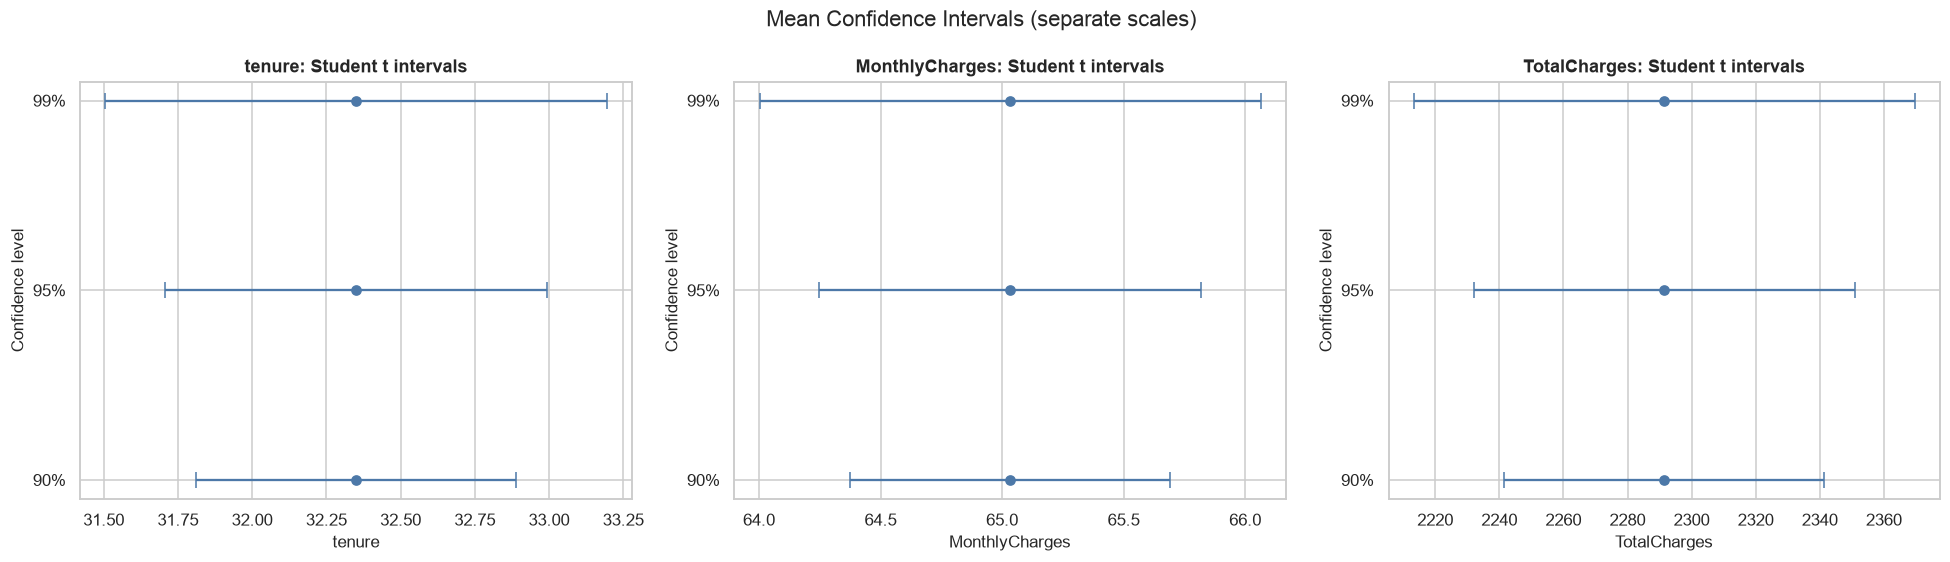

In [3]:
# ruff: noqa: E501
def mean_t_interval(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = values.size
    if n < 2:
        return {key: np.nan for key in ["sample_size", "sample_mean", "sample_sd", "standard_error", "degrees_of_freedom", "critical_t", "margin_of_error", "lower", "upper", "interval_width"]}
    mean = values.mean()
    sd = values.std(ddof=1)
    se = sd / np.sqrt(n)
    dfree = n - 1
    critical = stats.t.ppf((1 + confidence) / 2, dfree)
    margin = critical * se
    return {"sample_size": n, "sample_mean": mean, "sample_sd": sd, "standard_error": se, "degrees_of_freedom": dfree, "critical_t": critical, "margin_of_error": margin, "lower": mean - margin, "upper": mean + margin, "interval_width": 2 * margin}


mean_ci_rows = []
for variable in ["tenure", "MonthlyCharges", "TotalCharges"]:
    for confidence in [0.90, 0.95, 0.99]:
        mean_ci_rows.append({"variable": variable, "confidence_level": confidence, **mean_t_interval(df[variable], confidence)})
mean_ci_table = pd.DataFrame(mean_ci_rows)
display(mean_ci_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for axis, variable in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"], strict=True):
    view = mean_ci_table[mean_ci_table["variable"].eq(variable)]
    axis.errorbar(view["sample_mean"], view["confidence_level"].mul(100).astype(int).astype(str) + "%", xerr=[view["sample_mean"] - view["lower"], view["upper"] - view["sample_mean"]], fmt="o", capsize=5, color="#4C78A8")
    axis.set(title=f"{variable}: Student t intervals", xlabel=variable, ylabel="Confidence level")
fig.suptitle("Mean Confidence Intervals (separate scales)")
fig.tight_layout()
plt.show()

The dot is the point estimate; each horizontal bar is the range generated by its confidence
procedure. The nested pattern visualizes the cost of higher confidence. Separate panels are
essential because tenure, monthly charges, and accumulated charges have different units and
scales. These intervals quantify uncertainty in means, not the spread of individual values.

## 4. Confidence intervals for a binomial proportion

For $x$ successes among $n$ observations, the Wald interval is
$\hat p\pm z_{1-\alpha/2}\sqrt{\hat p(1-\hat p)/n}$. It is simple and symmetric but can
extend outside $[0,1]$, collapse at $x=0$ or $x=n$, and have poor small-sample or boundary
coverage. We therefore return its raw endpoints—no silent clipping.

The **Wilson score** interval inverts a score statistic. With $z=z_{1-\alpha/2}$, its
center and half-width use denominator $1+z^2/n$:

$$\frac{\hat p+z^2/(2n)\ \pm\ z\sqrt{\hat p(1-\hat p)/n+z^2/(4n^2)}}{1+z^2/n}.$$

It remains within probability bounds, is asymmetric when appropriate, and generally has
better coverage, making it the routine default here. The **Clopper–Pearson** interval
inverts exact binomial tails via beta quantiles. Its coverage is at least nominal under the
binomial model but it is often conservative and wider. Empty samples are undefined; zero
and all-success samples remain distinguishable and valid for Wilson/exact methods.

In [4]:
# ruff: noqa: E501
def proportion_interval(successes, n, confidence=0.95, method="wilson"):
    if n < 0 or successes < 0 or successes > n:
        raise ValueError("Require 0 <= successes <= n.")
    if n == 0:
        return (np.nan, np.nan)
    alpha = 1 - confidence
    p = successes / n
    z = stats.norm.ppf(1 - alpha / 2)
    if method == "wald":
        margin = z * np.sqrt(p * (1 - p) / n)
        return (p - margin, p + margin)  # deliberately not clipped
    if method == "wilson":
        denominator = 1 + z**2 / n
        center = (p + z**2 / (2 * n)) / denominator
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
        return (center - half, center + half)
    if method == "clopper-pearson":
        lower = 0.0 if successes == 0 else stats.beta.ppf(alpha / 2, successes, n - successes + 1)
        upper = 1.0 if successes == n else stats.beta.ppf(1 - alpha / 2, successes + 1, n - successes)
        return (lower, upper)
    raise ValueError(f"Unknown method: {method}")


overall_n = len(df)
overall_x = int(analysis_df["_churned"].sum())
proportion_rows = []
for confidence in [0.90, 0.95, 0.99]:
    for method in ["wald", "wilson", "clopper-pearson"]:
        lower, upper = proportion_interval(overall_x, overall_n, confidence, method)
        proportion_rows.append({"method": method, "confidence_level": confidence, "sample_size": overall_n, "churn_count": overall_x, "observed_churn_rate": overall_x / overall_n, "lower": lower, "upper": upper, "interval_width": upper - lower, "symmetric_about_estimate": np.isclose(overall_x / overall_n - lower, upper - overall_x / overall_n)})
overall_proportion_ci = pd.DataFrame(proportion_rows)
display(overall_proportion_ci)

boundary_examples = []
for label, x, n in [("empty", 0, 0), ("zero successes", 0, 10), ("one in ten", 1, 10), ("nine in ten", 9, 10), ("all successes", 10, 10)]:
    row = {"example": label, "successes": x, "sample_size": n}
    for method in ["wald", "wilson", "clopper-pearson"]:
        row[f"{method}_lower"], row[f"{method}_upper"] = proportion_interval(x, n, 0.95, method)
    boundary_examples.append(row)
boundary_example_table = pd.DataFrame(boundary_examples)
display(boundary_example_table)
print("Synthetic Wald example x=1, n=10 extends below 0; x=9, n=10 extends above 1. Clipping would hide poor calibration and alter coverage rather than fix the method.")

,method,confidence_level,sample_size,churn_count,observed_churn_rate,lower,upper,interval_width,symmetric_about_estimate
0,wald,0.900000,5634,1495,0.265353,0.255678,0.275029,0.019351,True
1,wilson,0.900000,5634,1495,0.265353,0.255792,0.275140,0.019348,False
2,clopper-pearson,0.900000,5634,1495,0.265353,0.255680,0.275206,0.019526,False
3,wald,0.950000,5634,1495,0.265353,0.253824,0.276882,0.023058,True
4,wilson,0.950000,5634,1495,0.265353,0.253987,0.277039,0.023052,False
5,clopper-pearson,0.950000,5634,1495,0.265353,0.253859,0.277091,0.023231,False
6,wald,0.990000,5634,1495,0.265353,0.250202,0.280505,0.030303,True
7,wilson,0.990000,5634,1495,0.265353,0.250484,0.280774,0.030291,False
8,clopper-pearson,0.990000,5634,1495,0.265353,0.250317,0.280789,0.030472,False


,example,successes,sample_size,wald_lower,wald_upper,wilson_lower,wilson_upper,clopper-pearson_lower,clopper-pearson_upper
0,empty,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,zero successes,0,10,0.000000,0.000000,0.000000,0.277533,0.000000,0.308497
2,one in ten,1,10,-0.085939,0.285939,0.017876,0.404150,0.002529,0.445016
3,nine in ten,9,10,0.714061,1.085939,0.595850,0.982124,0.554984,0.997471
4,all successes,10,10,1.000000,1.000000,0.722467,1.000000,0.691503,1.000000


Synthetic Wald example x=1, n=10 extends below 0; x=9, n=10 extends above 1. Clipping would hide poor calibration and alter coverage rather than fix the method.


## 5. Segment-level 95% Wilson intervals

The following temporary columns reproduce notebook 07 exactly: configured lifecycle
boundaries, observed monthly-charge quartiles, and the five-way internet eligibility /
security / support profile. All observed categories—including sparse and zero-churn
groups—are retained. A zero-churn group has $x=0$, whereas an empty group has $n=0$ and no
defined observed rate. Wilson's positive upper bound for $x=0$ correctly shows that zero
observed events do not prove zero underlying probability.

In [5]:
# ruff: noqa: E501
tenure_labels = ["0–6: Onboarding", "7–12: First year", "13–24: Developing", "25–48: Established", "49–72: Mature"]
analysis_df["Customer lifecycle"] = pd.cut(analysis_df["tenure"], bins=config["eda"]["tenure_boundaries"], labels=tenure_labels, include_lowest=True, ordered=True)
charge_quartiles = analysis_df["MonthlyCharges"].quantile([0.25, 0.50, 0.75])
analysis_df["Monthly-charge quartile"] = pd.cut(analysis_df["MonthlyCharges"], bins=[-np.inf, *charge_quartiles.tolist(), np.inf], labels=["Q1 Lower", "Q2 Lower-middle", "Q3 Upper-middle", "Q4 Higher"], include_lowest=True, ordered=True)
analysis_df["Combined support/security adoption"] = np.select(
    [analysis_df["InternetService"].eq("No"), analysis_df["OnlineSecurity"].eq("Yes") & analysis_df["TechSupport"].eq("Yes"), analysis_df["OnlineSecurity"].eq("Yes") & analysis_df["TechSupport"].ne("Yes"), analysis_df["OnlineSecurity"].ne("Yes") & analysis_df["TechSupport"].eq("Yes")],
    ["Not internet-eligible", "Security + support", "Security only", "Support only"],
    default="Neither security nor support",
)


def segment_wilson_table(data, dimension, label=None):
    rows = []
    grouped = data.groupby(dimension, observed=True, dropna=False)
    for segment, group in grouped:
        n = len(group)
        x = int(group["_churned"].sum())
        lower, upper = proportion_interval(x, n, 0.95, "wilson")
        rows.append({"dimension": label or (" × ".join(dimension) if isinstance(dimension, list) else dimension), "segment_name": " | ".join(map(str, segment)) if isinstance(segment, tuple) else str(segment), "customer_count": n, "churn_count": x, "observed_churn_rate": x / n if n else np.nan, "lower": lower, "upper": upper, "interval_width": upper - lower, "sparse_group": n < minimum_group_size, "zero_churn_observed": n > 0 and x == 0, "empty_group": n == 0})
    return pd.DataFrame(rows)


segment_dimensions = ["Contract", "Customer lifecycle", "PaymentMethod", "InternetService", "TechSupport", "OnlineSecurity", "Monthly-charge quartile", "Combined support/security adoption"]
segment_ci_table = pd.concat([segment_wilson_table(analysis_df, dimension) for dimension in segment_dimensions], ignore_index=True)
contract_lifecycle_ci = segment_wilson_table(analysis_df, ["Contract", "Customer lifecycle"], "Selected contract–lifecycle combinations")
segment_ci_table = pd.concat([segment_ci_table, contract_lifecycle_ci], ignore_index=True)
display(segment_ci_table)
print(f"Sparse observed groups retained: {segment_ci_table['sparse_group'].sum()}; zero-churn observed groups: {segment_ci_table['zero_churn_observed'].sum()}; empty groups: {segment_ci_table['empty_group'].sum()}")

,dimension,segment_name,customer_count,churn_count,observed_churn_rate,lower,upper,interval_width,sparse_group,zero_churn_observed,empty_group
0,Contract,Month-to-month,3095,1326,0.428433,0.411098,0.445945,0.034846,False,False,False
1,Contract,One year,1178,130,0.110357,0.093714,0.129532,0.035817,False,False,False
2,Contract,Two year,1361,39,0.028655,0.021032,0.038932,0.017900,False,False,False
3,Customer lifecycle,0–6: Onboarding,1191,628,0.527288,0.498892,0.555509,0.056617,False,False,False
4,Customer lifecycle,7–12: First year,565,204,0.361062,0.322519,0.401482,0.078963,False,False,False
5,Customer lifecycle,13–24: Developing,810,234,0.288889,0.258730,0.321041,0.062311,False,False,False
6,Customer lifecycle,25–48: Established,1272,261,0.205189,0.183899,0.228254,0.044354,False,False,False
7,Customer lifecycle,49–72: Mature,1796,168,0.093541,0.080928,0.107889,0.026961,False,False,False
8,PaymentMethod,Bank transfer (automatic),1246,200,0.160514,0.141179,0.181935,0.040755,False,False,False
9,PaymentMethod,Credit card (automatic),1215,190,0.156379,0.137042,0.177881,0.040839,False,False,False


Sparse observed groups retained: 1; zero-churn observed groups: 3; empty groups: 0


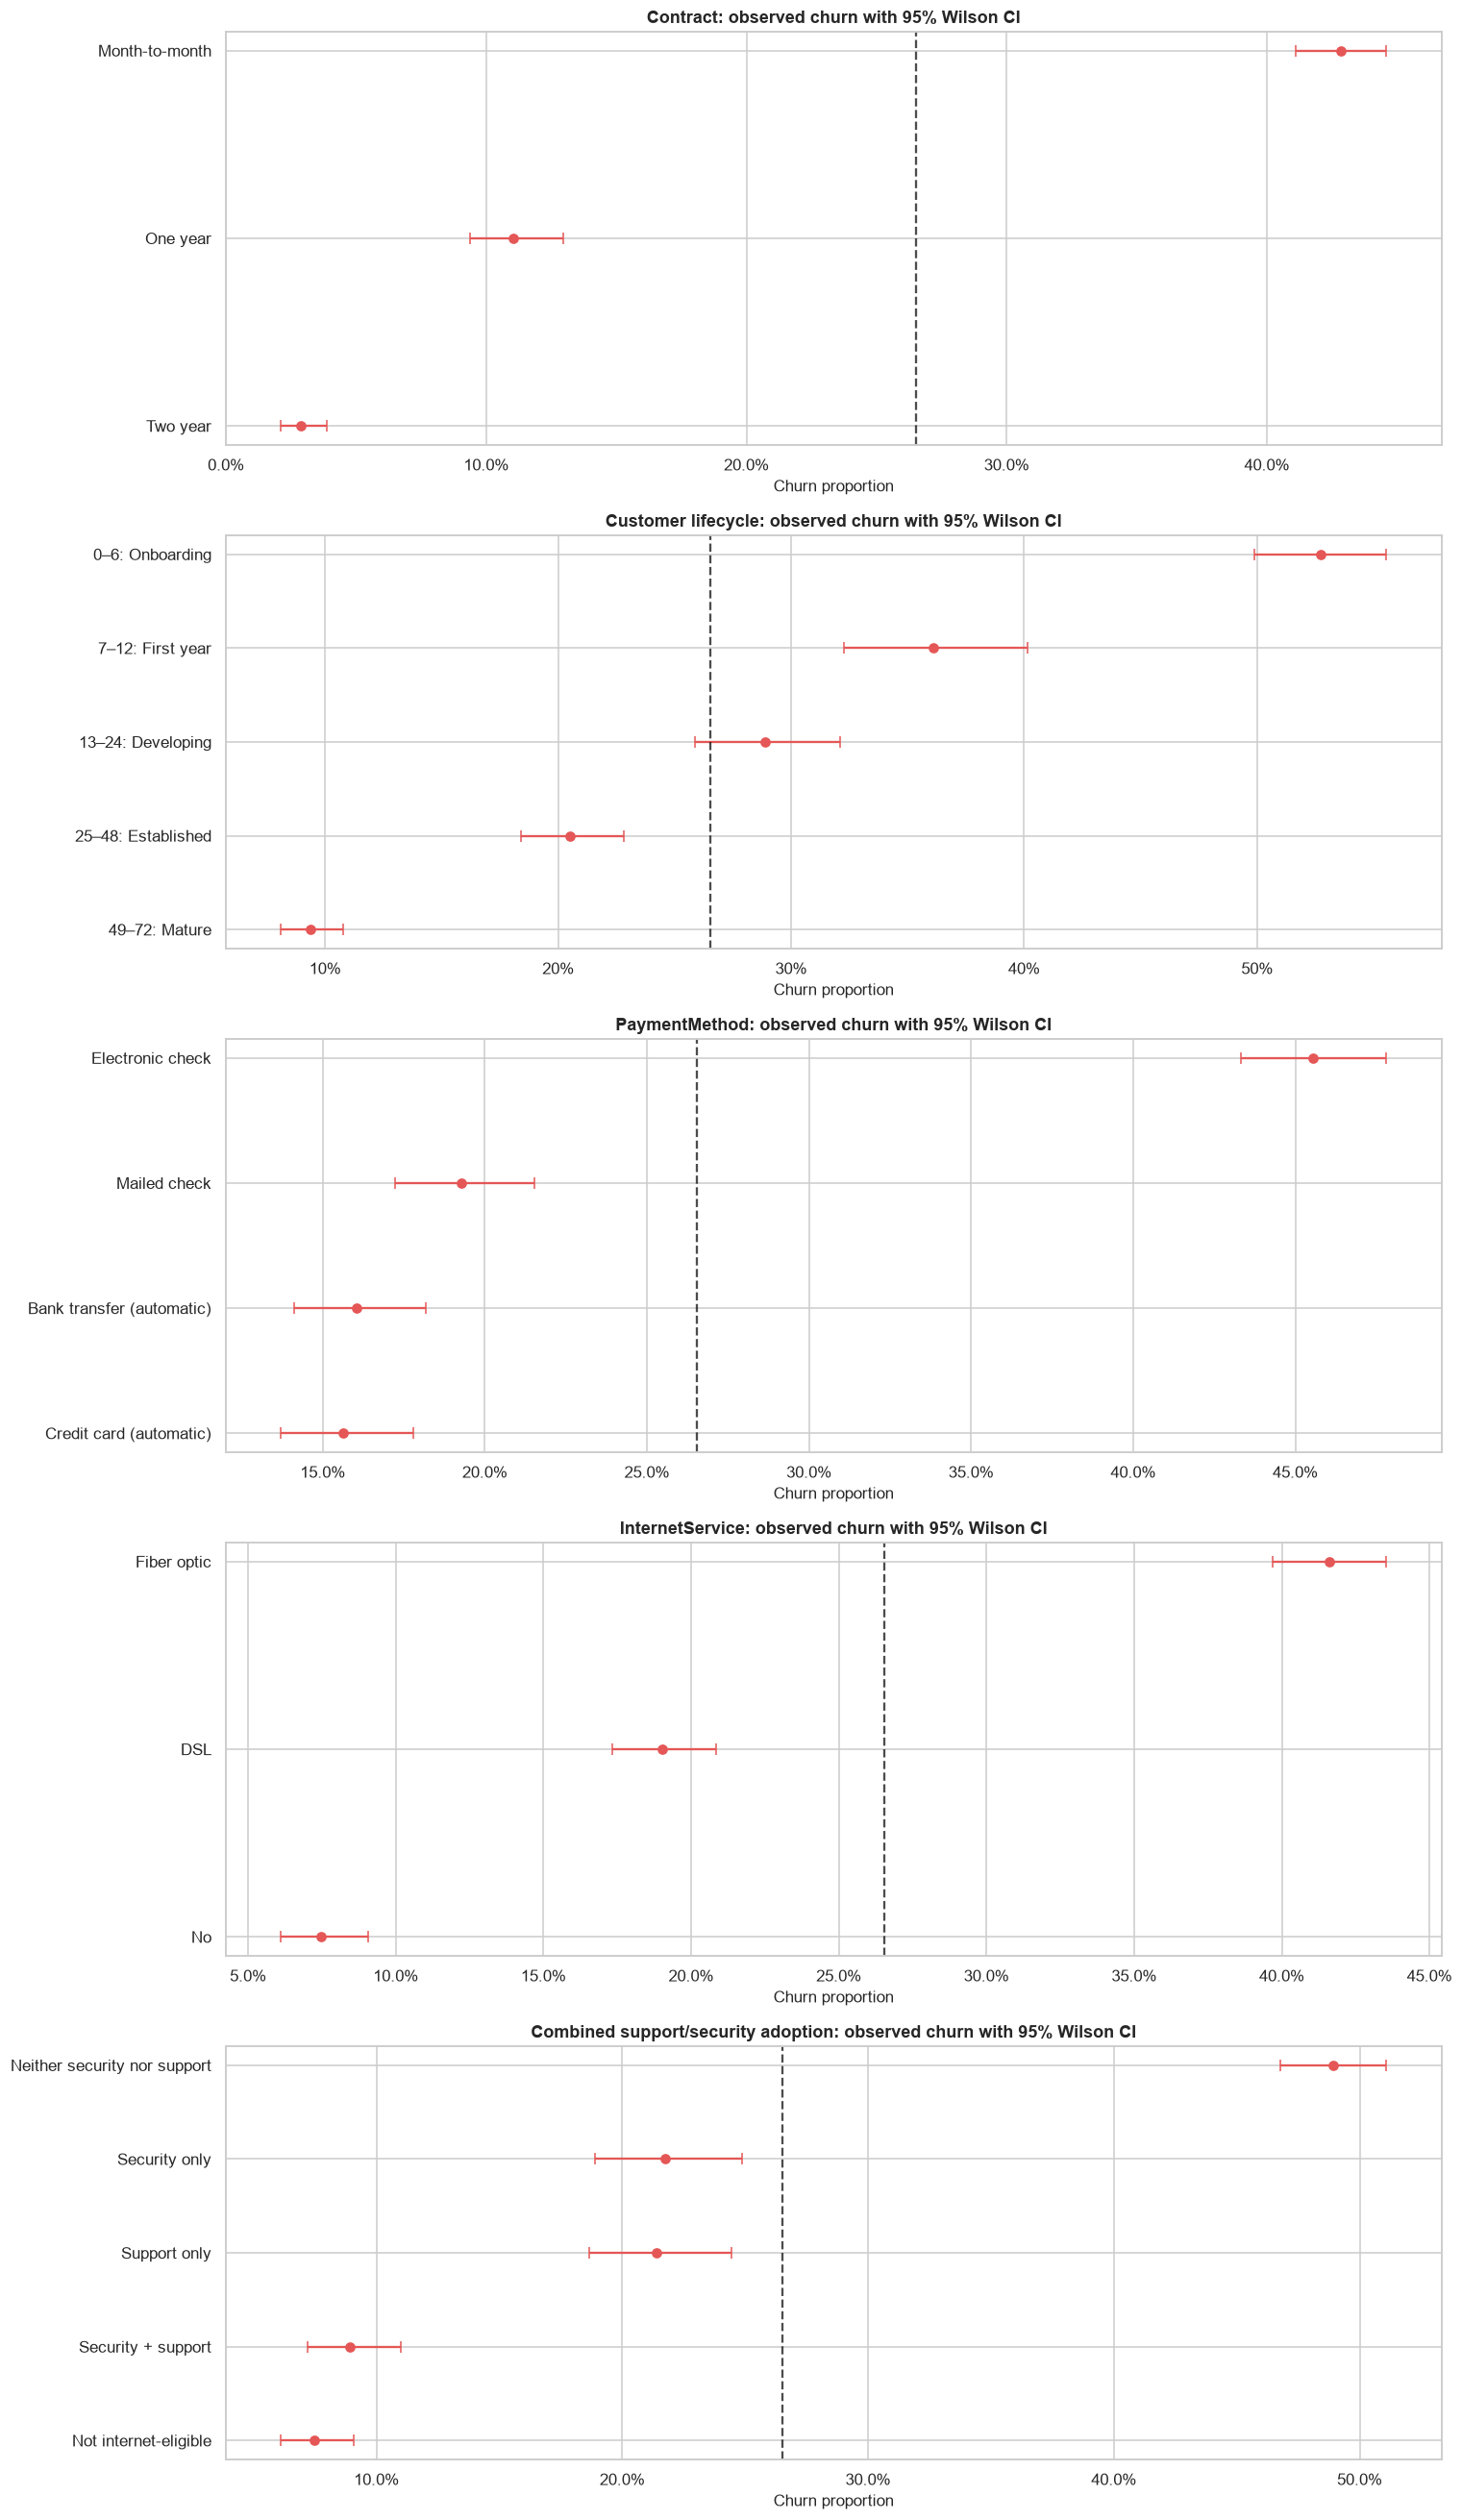

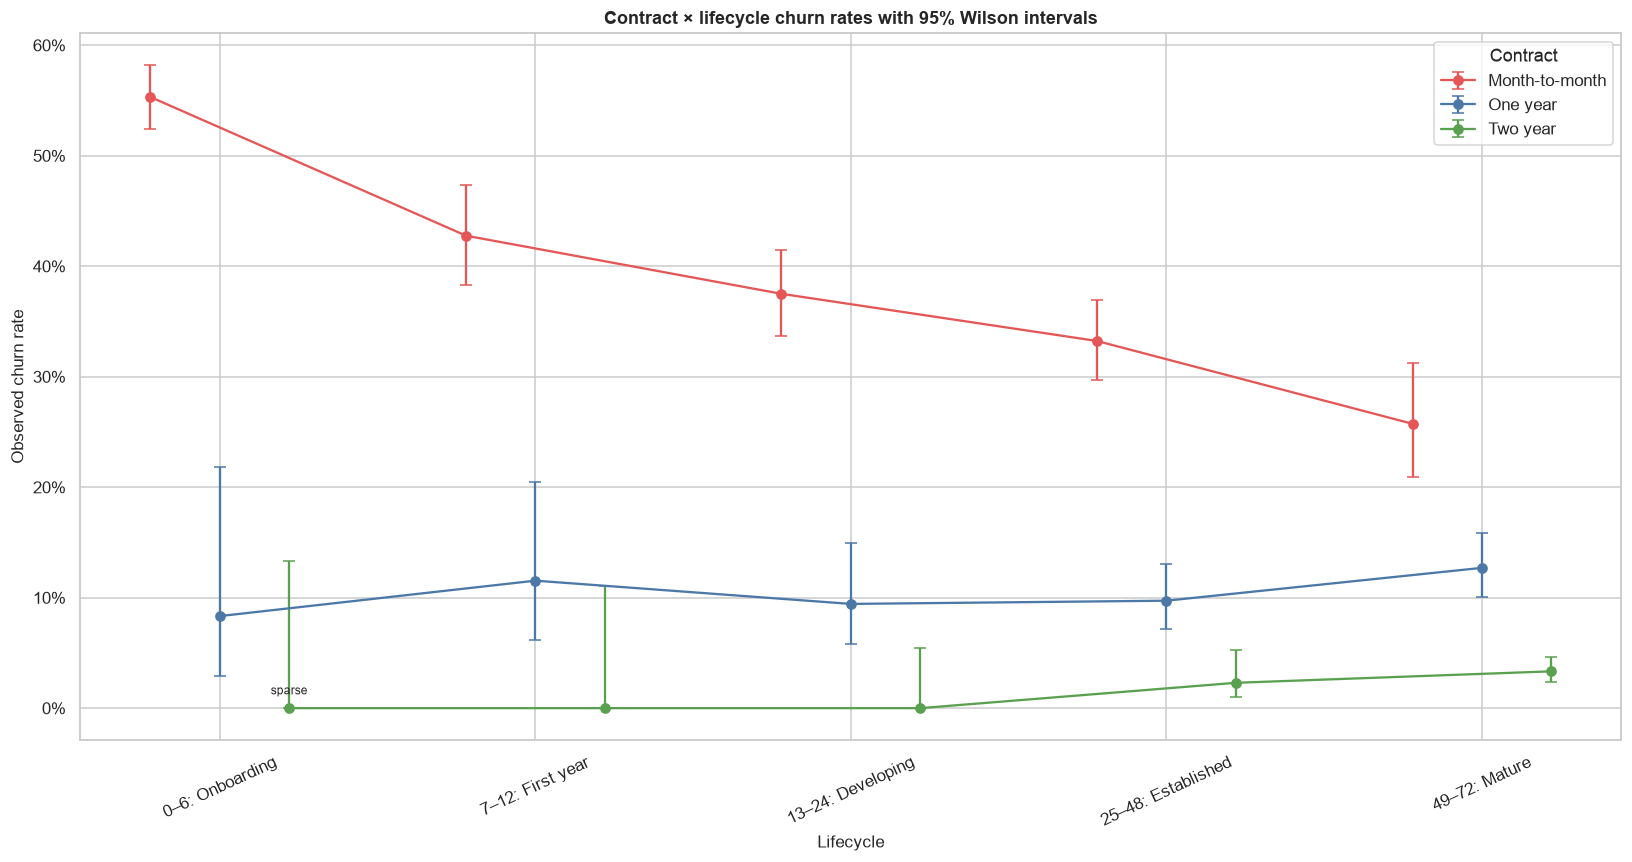

In [6]:
# ruff: noqa: E501
forest_dimensions = ["Contract", "Customer lifecycle", "PaymentMethod", "InternetService", "Combined support/security adoption"]
fig, axes = plt.subplots(len(forest_dimensions), 1, figsize=(14, 24))
for axis, dimension in zip(axes, forest_dimensions, strict=True):
    view = segment_ci_table[segment_ci_table["dimension"].eq(dimension)].sort_values("observed_churn_rate")
    labels = view["segment_name"] + np.where(view["sparse_group"], "  [sparse]", "")
    axis.errorbar(view["observed_churn_rate"], labels, xerr=[view["observed_churn_rate"] - view["lower"], view["upper"] - view["observed_churn_rate"]], fmt="o", capsize=4, color="#E45756")
    axis.axvline(overall_x / overall_n, color="black", linestyle="--", alpha=0.7)
    axis.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    axis.set(title=f"{dimension}: observed churn with 95% Wilson CI", xlabel="Churn proportion", ylabel="")
fig.tight_layout()
plt.show()

conditional = contract_lifecycle_ci.copy()
conditional[["Contract", "lifecycle"]] = conditional["segment_name"].str.split(" | ", n=1, expand=True, regex=False)
fig, axis = plt.subplots(figsize=(15, 8))
x_positions = np.arange(len(tenure_labels))
offsets = {"Month-to-month": -0.22, "One year": 0.0, "Two year": 0.22}
colors = {"Month-to-month": "#E45756", "One year": "#4C78A8", "Two year": "#59A14F"}
for contract, offset in offsets.items():
    view = conditional[conditional["Contract"].eq(contract)].set_index("lifecycle").reindex(tenure_labels)
    estimate = view["observed_churn_rate"].to_numpy()
    lower_error = np.maximum(0, estimate - view["lower"].to_numpy())
    upper_error = np.maximum(0, view["upper"].to_numpy() - estimate)
    axis.errorbar(x_positions + offset, estimate, yerr=[lower_error, upper_error], fmt="o-", capsize=4, label=contract, color=colors[contract])
    for x_value, y_value, sparse in zip(x_positions + offset, estimate, view["sparse_group"], strict=True):
        if sparse:
            axis.annotate("sparse", (x_value, y_value), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axis.set(title="Contract × lifecycle churn rates with 95% Wilson intervals", xlabel="Lifecycle", ylabel="Observed churn rate", xticks=x_positions, xticklabels=tenure_labels)
axis.tick_params(axis="x", rotation=25)
axis.legend(title="Contract")
plt.tight_layout()
plt.show()

Forest plots combine magnitude and precision: smaller groups usually produce wider bars.
Intervals that overlap can still correspond to a nonzero interval for a difference, because
the standard error of the contrast is not read from marginal overlap alone. Conversely,
non-overlap is not a universal test rule. A formal, pre-specified comparison procedure is
needed; this notebook reports descriptive intervals only.

## 6. Welch intervals for differences in numerical means

The estimand direction is consistently **churned mean minus retained mean**. For independent
groups,

$$\widehat\Delta=\bar X_Y-\bar X_N,\qquad
SE(\widehat\Delta)=\sqrt{s_Y^2/n_Y+s_N^2/n_N},$$

$$\nu=\frac{(s_Y^2/n_Y+s_N^2/n_N)^2}
{(s_Y^2/n_Y)^2/(n_Y-1)+(s_N^2/n_N)^2/(n_N-1)},\qquad
CI=\widehat\Delta\pm t_{1-\alpha/2,\nu}SE.$$

Welch's method does not pool variances and therefore does not assume equal population
variances. It still assumes independent observations/groups and finite variances; exact
small-sample inference additionally relies on approximately normal group distributions.
Large samples make mean-based approximations more stable, but cannot correct dependence or
selection bias. No hypothesis-test p-values are calculated.

,variable,churned_n,retained_n,churned_mean,retained_mean,churned_variance,retained_variance,mean_difference_churned_minus_retained,standard_error,welch_degrees_of_freedom,lower,upper,interval_width
0,tenure,1495,4139,17.955184,37.548925,381.661310,582.939305,-19.593741,0.629391,"3,241.001497",-20.827785,-18.359697,2.468087
1,MonthlyCharges,1495,4139,74.467659,61.624777,601.176790,966.219555,12.842882,0.797225,"3,327.249982",11.279781,14.405983,3.126202
2,TotalCharges,1495,4139,"1,529.878829","2,566.501474","3,556,482.219958","5,489,606.641280","-1,036.622644",60.870602,"3,258.585416","-1,155.971162",-917.274126,238.697036


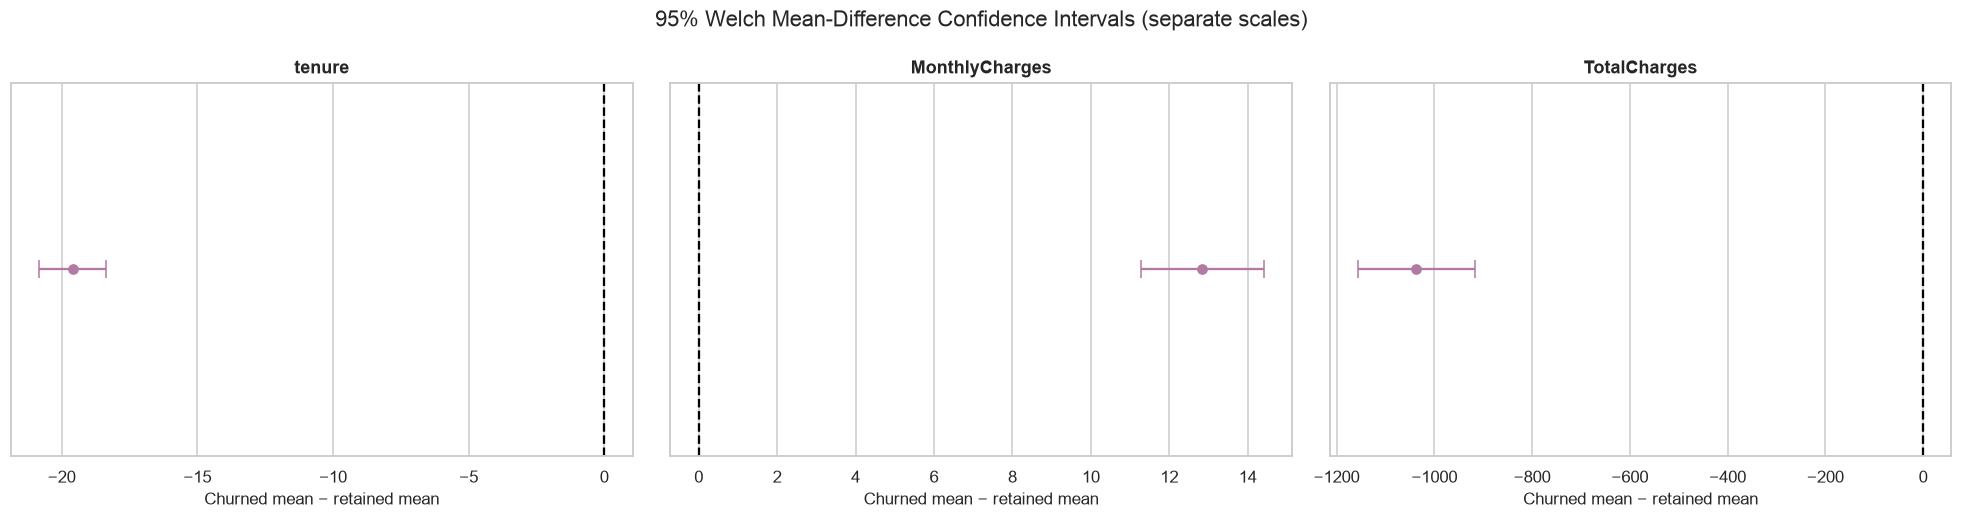

In [7]:
# ruff: noqa: E501
def welch_mean_difference(churned, retained, confidence=0.95):
    a, b = np.asarray(churned, float), np.asarray(retained, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    n1, n0 = len(a), len(b)
    m1, m0 = a.mean(), b.mean()
    v1, v0 = a.var(ddof=1), b.var(ddof=1)
    se = np.sqrt(v1 / n1 + v0 / n0)
    dfree = (v1 / n1 + v0 / n0) ** 2 / ((v1 / n1) ** 2 / (n1 - 1) + (v0 / n0) ** 2 / (n0 - 1))
    critical = stats.t.ppf((1 + confidence) / 2, dfree)
    difference = m1 - m0
    return {"churned_n": n1, "retained_n": n0, "churned_mean": m1, "retained_mean": m0, "churned_variance": v1, "retained_variance": v0, "mean_difference_churned_minus_retained": difference, "standard_error": se, "welch_degrees_of_freedom": dfree, "lower": difference - critical * se, "upper": difference + critical * se, "interval_width": 2 * critical * se}


welch_rows = []
for variable in ["tenure", "MonthlyCharges", "TotalCharges"]:
    welch_rows.append({"variable": variable, **welch_mean_difference(analysis_df.loc[analysis_df["_churned"], variable], analysis_df.loc[~analysis_df["_churned"], variable])})
welch_ci_table = pd.DataFrame(welch_rows)
display(welch_ci_table)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for axis, (_, row) in zip(axes, welch_ci_table.iterrows(), strict=True):
    estimate = row["mean_difference_churned_minus_retained"]
    axis.errorbar(estimate, [0], xerr=[[estimate - row["lower"]], [row["upper"] - estimate]], fmt="o", capsize=6, color="#B279A2")
    axis.axvline(0, color="black", linestyle="--")
    axis.set(title=row["variable"], xlabel="Churned mean − retained mean", yticks=[])
fig.suptitle("95% Welch Mean-Difference Confidence Intervals (separate scales)")
fig.tight_layout()
plt.show()

## 7. Newcombe intervals for independent churn-proportion differences

For two mutually exclusive groups, the descriptive estimand is
$\Delta=p_1-p_2$. Newcombe's method combines the two Wilson score limits without using a
potentially poor Wald approximation for the difference. If $(l_i,u_i)$ are Wilson limits,

$$L=\hat p_1-\hat p_2-\sqrt{(\hat p_1-l_1)^2+(u_2-\hat p_2)^2},$$
$$U=\hat p_1-\hat p_2+\sqrt{(u_1-\hat p_1)^2+(\hat p_2-l_2)^2}.$$

Every direction and mask is declared below. Independent-group formulas must not compare a
subgroup to the overall dataset because the observations overlap; such a comparison needs
dependence-aware treatment. These intervals are exploratory effect estimates, not formal
hypothesis tests.

In [8]:
# ruff: noqa: E501
def newcombe_difference(x1, n1, x2, n2, confidence=0.95):
    if n1 == 0 or n2 == 0:
        return (np.nan, np.nan)
    p1, p2 = x1 / n1, x2 / n2
    l1, u1 = proportion_interval(x1, n1, confidence, "wilson")
    l2, u2 = proportion_interval(x2, n2, confidence, "wilson")
    lower = p1 - p2 - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    upper = p1 - p2 + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return lower, upper


automatic_mask = analysis_df["PaymentMethod"].isin(["Bank transfer (automatic)", "Credit card (automatic)"])
internet_mask = analysis_df["InternetService"].ne("No")
comparisons = [
    ("Month-to-month − Two year", analysis_df["Contract"].eq("Month-to-month"), analysis_df["Contract"].eq("Two year"), "Contract categories; mutually exclusive"),
    ("Electronic check − automatic payments", analysis_df["PaymentMethod"].eq("Electronic check"), automatic_mask, "Automatic = bank transfer or credit card (automatic); mutually exclusive"),
    ("Fibre optic − DSL", analysis_df["InternetService"].eq("Fiber optic"), analysis_df["InternetService"].eq("DSL"), "InternetService categories; mutually exclusive"),
    ("Neither support/security − both services", internet_mask & analysis_df["OnlineSecurity"].ne("Yes") & analysis_df["TechSupport"].ne("Yes"), internet_mask & analysis_df["OnlineSecurity"].eq("Yes") & analysis_df["TechSupport"].eq("Yes"), "Restricted to internet subscribers; mutually exclusive adoption states"),
    ("Onboarding − Mature", analysis_df["Customer lifecycle"].eq("0–6: Onboarding"), analysis_df["Customer lifecycle"].eq("49–72: Mature"), "Established lifecycle endpoints; mutually exclusive"),
]
newcombe_rows = []
for comparison, mask1, mask2, definition in comparisons:
    assert not (mask1 & mask2).any()
    n1, n2 = int(mask1.sum()), int(mask2.sum())
    x1, x2 = int(analysis_df.loc[mask1, "_churned"].sum()), int(analysis_df.loc[mask2, "_churned"].sum())
    lower, upper = newcombe_difference(x1, n1, x2, n2)
    newcombe_rows.append({"comparison_direction": comparison, "definition": definition, "group_1_n": n1, "group_1_churn": x1, "group_1_proportion": x1 / n1, "group_2_n": n2, "group_2_churn": x2, "group_2_proportion": x2 / n2, "absolute_difference_percentage_points": 100 * (x1 / n1 - x2 / n2), "lower": lower, "upper": upper})
newcombe_ci_table = pd.DataFrame(newcombe_rows)
display(newcombe_ci_table)

,comparison_direction,definition,group_1_n,group_1_churn,group_1_proportion,group_2_n,group_2_churn,group_2_proportion,absolute_difference_percentage_points,lower,upper
0,Month-to-month − Two year,Contract categories; mutually exclusive,3095,1326,0.428433,1361,39,0.028655,39.977756,0.379626,0.418877
1,Electronic check − automatic payments,Automatic = bank transfer or credit card (auto...,1877,855,0.455514,2461,390,0.158472,29.704195,0.270093,0.323570
2,Fibre optic − DSL,InternetService categories; mutually exclusive,2493,1037,0.415965,1934,368,0.190279,22.568549,0.199295,0.251444
3,Neither support/security − both services,Restricted to internet subscribers; mutually e...,2050,1003,0.489268,875,78,0.089143,40.012544,0.370195,0.427723
4,Onboarding − Mature,Established lifecycle endpoints; mutually excl...,1191,628,0.527288,1796,168,0.093541,43.374679,0.401931,0.464658


## 8. Bootstrap foundations

The **nonparametric bootstrap** samples $n$ complete observed rows with replacement from
the empirical distribution, calculates an estimator $\hat\theta^{*b}$ for each of $B$
replicates, and treats those replicates as an empirical sampling distribution. The
bootstrap standard error is

$$\widehat{SE}_{boot}=\sqrt{\frac{1}{B-1}\sum_{b=1}^B
(\hat\theta^{*b}-\overline{\theta^*})^2},$$

and estimated bias is $\overline{\theta^*}-\hat\theta$.

- **Percentile:** empirical $\alpha/2$ and $1-\alpha/2$ quantiles.
- **Basic:** $[2\hat\theta-q_{1-\alpha/2},\ 2\hat\theta-q_{\alpha/2}]$; reflects the
  bootstrap error around the point estimate.
- **BCa:** adjusts percentile probabilities for median bias $z_0$ and acceleration $a$:
  $\alpha'=\Phi[z_0+(z_0+z_\alpha)/(1-a(z_0+z_\alpha))]$. Jackknife leave-one-out
  estimates provide acceleration.

BCa can improve transformation behavior and account for skew/bias, but it can be unstable
with ties, nonsmooth estimators, degenerate distributions, undefined acceleration, or too
few effective outcomes. Bootstrap validity still depends on a representative empirical
distribution and appropriate resampling unit. It does **not** create new independent
customer information, correct selection bias, balance classes, or perform bagging. Class
balancing changes a training distribution; bagging aggregates fitted learners; neither is
the uncertainty task here.

In [9]:
# ruff: noqa: E501
B = 5_000
batch_size = 100
n = len(analysis_df)
monthly = analysis_df["MonthlyCharges"].to_numpy(float)
tenure = analysis_df["tenure"].to_numpy(float)
total = analysis_df["TotalCharges"].to_numpy(float)
churn = analysis_df["_churned"].to_numpy(bool)

estimator_names = ["Mean MonthlyCharges", "Median MonthlyCharges", "Mean tenure", "Median TotalCharges", "Overall churn proportion", "MonthlyCharges mean difference: churned − retained", "Tenure median difference: churned − retained", "Churn-associated share of monthly charges"]
bootstrap_values = {name: np.empty(B, dtype=float) for name in estimator_names}

position = 0
while position < B:
    size = min(batch_size, B - position)
    indices = rng.integers(0, n, size=(size, n))
    month_b = monthly[indices]
    tenure_b = tenure[indices]
    total_b = total[indices]
    churn_b = churn[indices]
    retained_b = ~churn_b
    churn_count_b = churn_b.sum(axis=1)
    retained_count_b = retained_b.sum(axis=1)
    bootstrap_values[estimator_names[0]][position:position + size] = month_b.mean(axis=1)
    bootstrap_values[estimator_names[1]][position:position + size] = np.median(month_b, axis=1)
    bootstrap_values[estimator_names[2]][position:position + size] = tenure_b.mean(axis=1)
    bootstrap_values[estimator_names[3]][position:position + size] = np.median(total_b, axis=1)
    bootstrap_values[estimator_names[4]][position:position + size] = churn_b.mean(axis=1)
    bootstrap_values[estimator_names[5]][position:position + size] = (month_b * churn_b).sum(axis=1) / churn_count_b - (month_b * retained_b).sum(axis=1) / retained_count_b
    bootstrap_values[estimator_names[6]][position:position + size] = np.nanmedian(np.where(churn_b, tenure_b, np.nan), axis=1) - np.nanmedian(np.where(retained_b, tenure_b, np.nan), axis=1)
    bootstrap_values[estimator_names[7]][position:position + size] = (month_b * churn_b).sum(axis=1) / month_b.sum(axis=1)
    position += size

point_estimates = {
    estimator_names[0]: monthly.mean(), estimator_names[1]: np.median(monthly), estimator_names[2]: tenure.mean(), estimator_names[3]: np.median(total), estimator_names[4]: churn.mean(),
    estimator_names[5]: monthly[churn].mean() - monthly[~churn].mean(), estimator_names[6]: np.median(tenure[churn]) - np.median(tenure[~churn]), estimator_names[7]: monthly[churn].sum() / monthly.sum(),
}
assert all(np.isfinite(values).all() for values in bootstrap_values.values())
print(f"Generated {B:,} complete-row bootstrap replicates in batches of at most {batch_size}; no resampled data were saved.")

Generated 5,000 complete-row bootstrap replicates in batches of at most 100; no resampled data were saved.


In [10]:
# ruff: noqa: E501
def bca_interval(replicates, point, jackknife, confidence=0.95):
    replicates = np.asarray(replicates, float)
    jackknife = np.asarray(jackknife, float)
    if np.unique(replicates).size < 2 or np.unique(jackknife).size < 2:
        return (np.nan, np.nan, "degenerate distribution")
    prop_less = np.clip((np.sum(replicates < point) + 0.5 * np.sum(replicates == point)) / len(replicates), 1 / (2 * len(replicates)), 1 - 1 / (2 * len(replicates)))
    z0 = stats.norm.ppf(prop_less)
    centered = jackknife.mean() - jackknife
    denominator = 6 * np.sum(centered**2) ** 1.5
    if not np.isfinite(denominator) or denominator == 0:
        return (np.nan, np.nan, "undefined jackknife acceleration")
    acceleration = np.sum(centered**3) / denominator
    alpha = 1 - confidence
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    adjusted = stats.norm.cdf(z0 + (z0 + z) / (1 - acceleration * (z0 + z)))
    if not np.isfinite(adjusted).all() or not (0 <= adjusted[0] < adjusted[1] <= 1):
        return (np.nan, np.nan, "invalid BCa adjusted probabilities")
    lower, upper = np.quantile(replicates, adjusted)
    return (lower, upper, f"z0={z0:.4f}; acceleration={acceleration:.6f}")


def smooth_jackknife(name):
    if name == estimator_names[0]:
        return (monthly.sum() - monthly) / (n - 1)
    if name == estimator_names[2]:
        return (tenure.sum() - tenure) / (n - 1)
    if name == estimator_names[4]:
        return (churn.sum() - churn.astype(int)) / (n - 1)
    if name == estimator_names[5]:
        sum_y, count_y = monthly[churn].sum(), churn.sum()
        sum_n, count_n = monthly[~churn].sum(), (~churn).sum()
        return np.where(churn, (sum_y - monthly) / (count_y - 1) - sum_n / count_n, sum_y / count_y - (sum_n - monthly) / (count_n - 1))
    if name == estimator_names[7]:
        numerator, denominator = monthly[churn].sum(), monthly.sum()
        return (numerator - monthly * churn) / (denominator - monthly)
    return None


bootstrap_rows = []
bootstrap_method_notes = []
for name in estimator_names:
    reps = bootstrap_values[name]
    point = point_estimates[name]
    q_low, q_high = np.quantile(reps, [0.025, 0.975])
    methods = [("percentile", q_low, q_high, "empirical quantiles"), ("basic", 2 * point - q_high, 2 * point - q_low, "reflected bootstrap quantiles")]
    jackknife = smooth_jackknife(name)
    if jackknife is not None:
        lower, upper, note = bca_interval(reps, point, jackknife)
        if np.isfinite([lower, upper]).all():
            methods.append(("BCa", lower, upper, note))
        else:
            bootstrap_method_notes.append({"estimator": name, "method": "BCa", "status": note})
    else:
        bootstrap_method_notes.append({"estimator": name, "method": "BCa", "status": "Not reported: median/nonsmooth estimator with ties; full delete-one jackknife is computationally disproportionate and may give unstable acceleration."})
    for method, lower, upper, note in methods:
        bootstrap_rows.append({"estimator": name, "original_point_estimate": point, "bootstrap_mean": reps.mean(), "estimated_bias": reps.mean() - point, "bootstrap_standard_error": reps.std(ddof=1), "lower": lower, "upper": upper, "interval_width": upper - lower, "replicates": B, "method": method, "method_note": note})

bootstrap_ci_table = pd.DataFrame(bootstrap_rows)
bootstrap_method_notes = pd.DataFrame(bootstrap_method_notes)
display(bootstrap_ci_table)
display(bootstrap_method_notes)

,estimator,original_point_estimate,bootstrap_mean,estimated_bias,bootstrap_standard_error,lower,upper,interval_width,replicates,method,method_note
0,Mean MonthlyCharges,65.032677,65.029693,-0.002984,0.403905,64.247806,65.829884,1.582077,5000,percentile,empirical quantiles
1,Mean MonthlyCharges,65.032677,65.029693,-0.002984,0.403905,64.235469,65.817547,1.582077,5000,basic,reflected bootstrap quantiles
2,Mean MonthlyCharges,65.032677,65.029693,-0.002984,0.403905,64.253724,65.838543,1.584818,5000,BCa,z0=0.0145; acceleration=-0.000522
3,Median MonthlyCharges,70.525000,70.578800,0.053800,0.412645,69.999375,71.650000,1.650625,5000,percentile,empirical quantiles
4,Median MonthlyCharges,70.525000,70.578800,0.053800,0.412645,69.400000,71.050625,1.650625,5000,basic,reflected bootstrap quantiles
5,Mean tenure,32.349663,32.355011,0.005348,0.329413,31.718206,32.996282,1.278075,5000,percentile,empirical quantiles
6,Mean tenure,32.349663,32.355011,0.005348,0.329413,31.703044,32.981119,1.278075,5000,basic,reflected bootstrap quantiles
7,Mean tenure,32.349663,32.355011,0.005348,0.329413,31.707823,32.987043,1.279219,5000,BCa,z0=-0.0100; acceleration=0.000534
8,Median TotalCharges,"1,395.525000","1,397.233185",1.708185,29.135826,"1,339.478750","1,453.100000",113.621250,5000,percentile,empirical quantiles
9,Median TotalCharges,"1,395.525000","1,397.233185",1.708185,29.135826,"1,337.950000","1,451.571250",113.621250,5000,basic,reflected bootstrap quantiles


,estimator,method,status
0,Median MonthlyCharges,BCa,Not reported: median/nonsmooth estimator with ...
1,Median TotalCharges,BCa,Not reported: median/nonsmooth estimator with ...
2,Tenure median difference: churned − retained,BCa,Not reported: median/nonsmooth estimator with ...


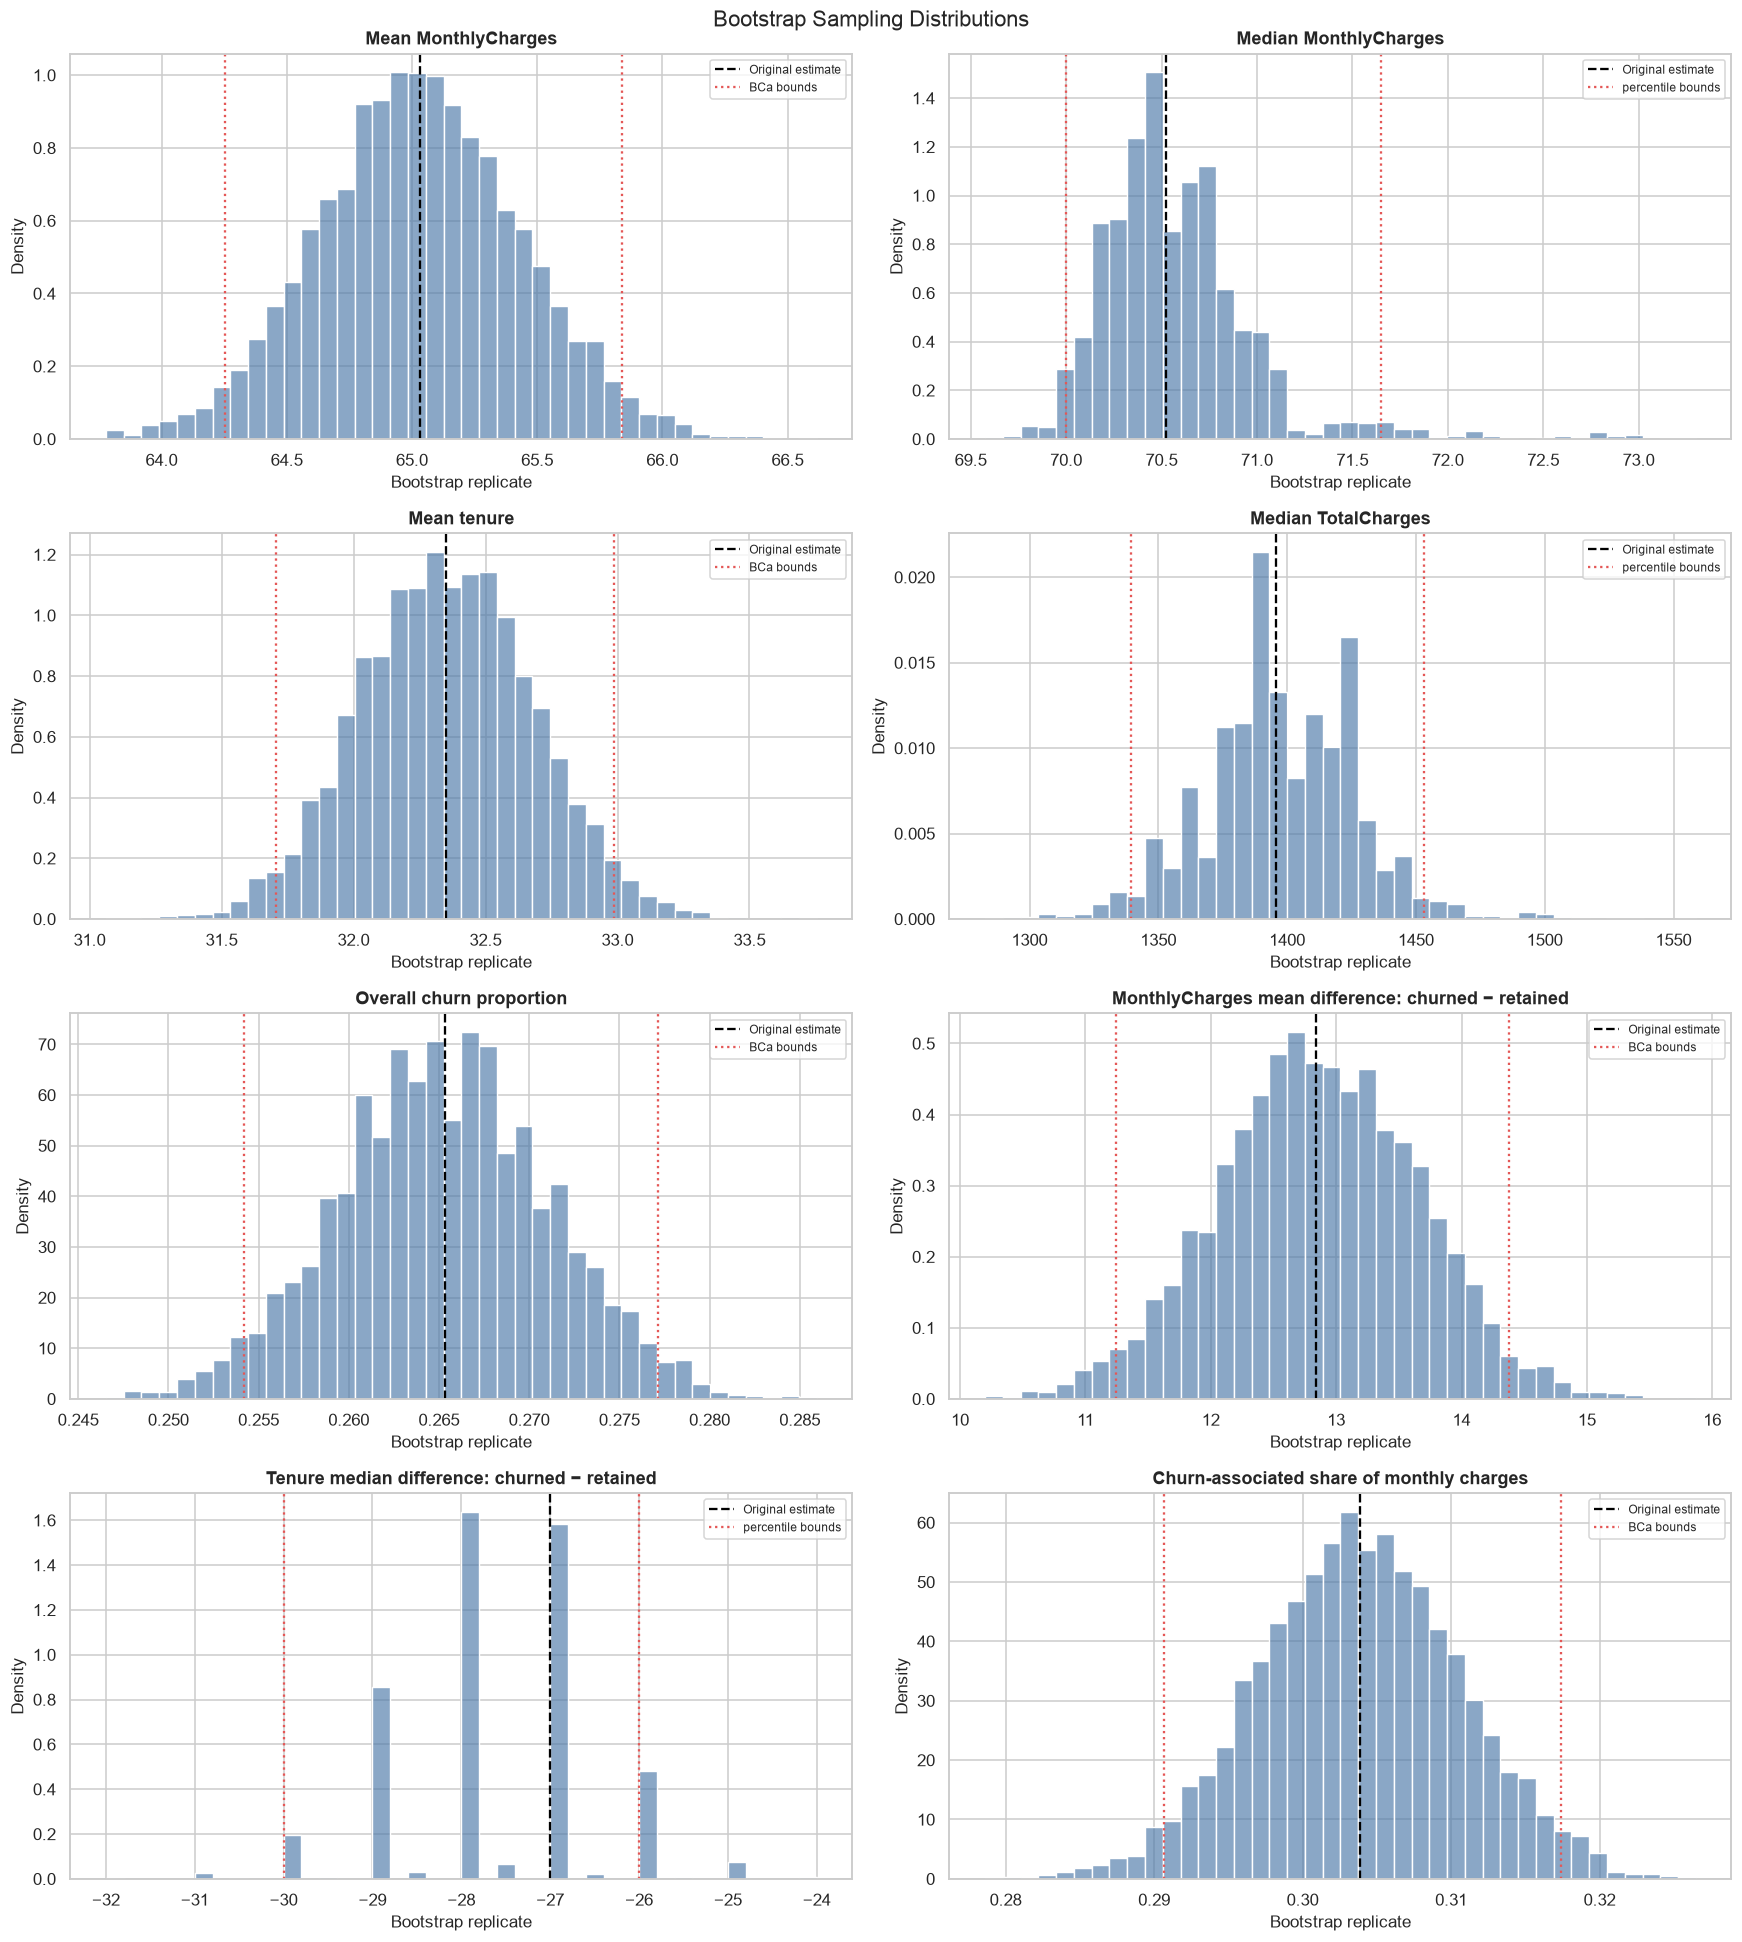

In [11]:
# ruff: noqa: E501
fig, axes = plt.subplots(4, 2, figsize=(16, 18))
for axis, name in zip(axes.flat, estimator_names, strict=True):
    reps = bootstrap_values[name]
    selected = bootstrap_ci_table[(bootstrap_ci_table["estimator"].eq(name)) & (bootstrap_ci_table["method"].eq("BCa"))]
    if selected.empty:
        selected = bootstrap_ci_table[(bootstrap_ci_table["estimator"].eq(name)) & (bootstrap_ci_table["method"].eq("percentile"))]
    row = selected.iloc[0]
    sns.histplot(reps, bins=40, stat="density", color="#4C78A8", alpha=0.65, ax=axis)
    axis.axvline(point_estimates[name], color="black", linestyle="--", label="Original estimate")
    axis.axvline(row["lower"], color="#E45756", linestyle=":", label=f"{row['method']} bounds")
    axis.axvline(row["upper"], color="#E45756", linestyle=":")
    axis.set(title=name, xlabel="Bootstrap replicate", ylabel="Density")
    axis.legend(fontsize=8)
fig.suptitle("Bootstrap Sampling Distributions")
fig.tight_layout()
plt.show()

## 9. Method comparison

Analytical $t$ intervals are fast and symmetric about a mean but rely on a mean sampling
approximation. Bootstrap intervals cost computation and can reflect estimator asymmetry;
percentile intervals are intuitive, basic intervals correct in the opposite direction of
observed bootstrap error, and BCa additionally adjusts median bias and local skewness.
Nonsmooth, tied medians make BCa acceleration less attractive here, so their percentile and
basic intervals are reported transparently.

For proportions, Wald is cheapest but least robust near boundaries or with small $n$;
Wilson is a strong general-purpose balance; exact Clopper–Pearson is conservative. The
narrowest interval is not automatically best: calibration, assumptions, estimand shape,
sample support, bias, and decision cost matter more than width alone.

In [12]:
# ruff: noqa: E501
t_vs_bootstrap = []
for variable, estimator in [("tenure", "Mean tenure"), ("MonthlyCharges", "Mean MonthlyCharges")]:
    t_row = mean_ci_table[(mean_ci_table["variable"].eq(variable)) & (mean_ci_table["confidence_level"].eq(0.95))].iloc[0]
    t_vs_bootstrap.append({"estimator": estimator, "method": "Student t", "lower": t_row["lower"], "upper": t_row["upper"], "interval_width": t_row["interval_width"], "symmetry": "symmetric", "cost": "closed form"})
    for _, row in bootstrap_ci_table[(bootstrap_ci_table["estimator"].eq(estimator))].iterrows():
        t_vs_bootstrap.append({"estimator": estimator, "method": row["method"], "lower": row["lower"], "upper": row["upper"], "interval_width": row["interval_width"], "symmetry": "data-adaptive" if row["method"] != "basic" else "reflected", "cost": f"{B:,} resamples"})
t_vs_bootstrap = pd.DataFrame(t_vs_bootstrap)
proportion_method_comparison = overall_proportion_ci[overall_proportion_ci["confidence_level"].eq(0.95)].copy()
bootstrap_method_comparison = bootstrap_ci_table[["estimator", "method", "estimated_bias", "lower", "upper", "interval_width", "method_note"]]
display(t_vs_bootstrap)
display(proportion_method_comparison)
display(bootstrap_method_comparison)

,estimator,method,lower,upper,interval_width,symmetry,cost
0,Mean tenure,Student t,31.707624,32.991702,1.284078,symmetric,closed form
1,Mean tenure,percentile,31.718206,32.996282,1.278075,data-adaptive,"5,000 resamples"
2,Mean tenure,basic,31.703044,32.981119,1.278075,reflected,"5,000 resamples"
3,Mean tenure,BCa,31.707823,32.987043,1.279219,data-adaptive,"5,000 resamples"
4,Mean MonthlyCharges,Student t,64.248544,65.816809,1.568264,symmetric,closed form
5,Mean MonthlyCharges,percentile,64.247806,65.829884,1.582077,data-adaptive,"5,000 resamples"
6,Mean MonthlyCharges,basic,64.235469,65.817547,1.582077,reflected,"5,000 resamples"
7,Mean MonthlyCharges,BCa,64.253724,65.838543,1.584818,data-adaptive,"5,000 resamples"


,method,confidence_level,sample_size,churn_count,observed_churn_rate,lower,upper,interval_width,symmetric_about_estimate
3,wald,0.950000,5634,1495,0.265353,0.253824,0.276882,0.023058,True
4,wilson,0.950000,5634,1495,0.265353,0.253987,0.277039,0.023052,False
5,clopper-pearson,0.950000,5634,1495,0.265353,0.253859,0.277091,0.023231,False


,estimator,method,estimated_bias,lower,upper,interval_width,method_note
0,Mean MonthlyCharges,percentile,-0.002984,64.247806,65.829884,1.582077,empirical quantiles
1,Mean MonthlyCharges,basic,-0.002984,64.235469,65.817547,1.582077,reflected bootstrap quantiles
2,Mean MonthlyCharges,BCa,-0.002984,64.253724,65.838543,1.584818,z0=0.0145; acceleration=-0.000522
3,Median MonthlyCharges,percentile,0.053800,69.999375,71.650000,1.650625,empirical quantiles
4,Median MonthlyCharges,basic,0.053800,69.400000,71.050625,1.650625,reflected bootstrap quantiles
5,Mean tenure,percentile,0.005348,31.718206,32.996282,1.278075,empirical quantiles
6,Mean tenure,basic,0.005348,31.703044,32.981119,1.278075,reflected bootstrap quantiles
7,Mean tenure,BCa,0.005348,31.707823,32.987043,1.279219,z0=-0.0100; acceleration=0.000534
8,Median TotalCharges,percentile,1.708185,"1,339.478750","1,453.100000",113.621250,empirical quantiles
9,Median TotalCharges,basic,1.708185,"1,337.950000","1,451.571250",113.621250,reflected bootstrap quantiles


## 10. Synthetic repeated-sampling coverage

Coverage can be assessed only when a generating parameter is known, so this section uses
synthetic data—not claims about a true telecom population. For each configuration, empirical
coverage is the share of intervals containing the known parameter. Its Monte Carlo standard
error is $\sqrt{\widehat C(1-\widehat C)/R}$, where $R=5{,}000$ repetitions.

Normal and lognormal examples assess Student mean intervals. The lognormal is scaled to
known mean 1 and is positively skewed. Binomial examples compare Wald, Wilson, and exact
intervals for $p\in\{.01,.05,.25,.50\}$ and $n\in\{10,30,100,500\}$. Nominal and empirical
coverage differ because finite-sample distributions are discrete or skewed and because
approximations need not be exact. Monte Carlo noise adds a smaller simulation error.

In [13]:
# ruff: noqa: E501
simulation_rng = np.random.default_rng(random_state)
R = 5_000
coverage_rows = []
for distribution in ["Normal", "Positively skewed lognormal"]:
    for sample_size in [10, 30, 100, 500]:
        if distribution == "Normal":
            samples = simulation_rng.normal(0, 1, size=(R, sample_size))
            truth = 0.0
        else:
            sigma_log = 1.0
            samples = simulation_rng.lognormal(mean=-sigma_log**2 / 2, sigma=sigma_log, size=(R, sample_size))
            truth = 1.0
        means = samples.mean(axis=1)
        ses = samples.std(axis=1, ddof=1) / np.sqrt(sample_size)
        critical = stats.t.ppf(0.975, sample_size - 1)
        lower, upper = means - critical * ses, means + critical * ses
        covered = (lower <= truth) & (truth <= upper)
        coverage = covered.mean()
        coverage_rows.append({"family": "mean", "distribution_or_probability": distribution, "sample_size": sample_size, "method": "Student t", "true_parameter": truth, "empirical_coverage": coverage, "average_interval_width": np.mean(upper - lower), "monte_carlo_se": np.sqrt(coverage * (1 - coverage) / R), "repetitions": R})


def vectorized_binomial_intervals(x, n, confidence, method):
    x = np.asarray(x)
    p = x / n
    alpha = 1 - confidence
    z = stats.norm.ppf(1 - alpha / 2)
    if method == "wald":
        half = z * np.sqrt(p * (1 - p) / n)
        return p - half, p + half
    if method == "wilson":
        denominator = 1 + z**2 / n
        center = (p + z**2 / (2 * n)) / denominator
        half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator
        return center - half, center + half
    lower = np.where(x == 0, 0.0, stats.beta.ppf(alpha / 2, x, n - x + 1))
    upper = np.where(x == n, 1.0, stats.beta.ppf(1 - alpha / 2, x + 1, n - x))
    return lower, upper


for true_p in [0.01, 0.05, 0.25, 0.50]:
    for sample_size in [10, 30, 100, 500]:
        successes = simulation_rng.binomial(sample_size, true_p, size=R)
        for method in ["wald", "wilson", "clopper-pearson"]:
            lower, upper = vectorized_binomial_intervals(successes, sample_size, 0.95, method)
            covered = (lower <= true_p) & (true_p <= upper)
            coverage = covered.mean()
            coverage_rows.append({"family": "binomial proportion", "distribution_or_probability": f"p={true_p:.2f}", "sample_size": sample_size, "method": method, "true_parameter": true_p, "empirical_coverage": coverage, "average_interval_width": np.mean(upper - lower), "monte_carlo_se": np.sqrt(coverage * (1 - coverage) / R), "repetitions": R})

coverage_simulation = pd.DataFrame(coverage_rows)
display(coverage_simulation)

,family,distribution_or_probability,sample_size,method,true_parameter,empirical_coverage,average_interval_width,monte_carlo_se,repetitions
0,mean,Normal,10,Student t,0.000000,0.949400,1.394864,0.003100,5000
1,mean,Normal,30,Student t,0.000000,0.954800,0.742595,0.002938,5000
2,mean,Normal,100,Student t,0.000000,0.951000,0.395700,0.003053,5000
3,mean,Normal,500,Student t,0.000000,0.947800,0.175578,0.003146,5000
4,mean,Positively skewed lognormal,10,Student t,1.000000,0.841000,1.515623,0.005171,5000
5,mean,Positively skewed lognormal,30,Student t,1.000000,0.879200,0.869422,0.004609,5000
6,mean,Positively skewed lognormal,100,Student t,1.000000,0.919400,0.486826,0.003850,5000
7,mean,Positively skewed lognormal,500,Student t,1.000000,0.936200,0.226651,0.003456,5000
8,binomial proportion,p=0.01,10,wald,0.010000,0.092800,0.035219,0.004103,5000
9,binomial proportion,p=0.01,10,wilson,0.010000,0.907000,0.287989,0.004107,5000


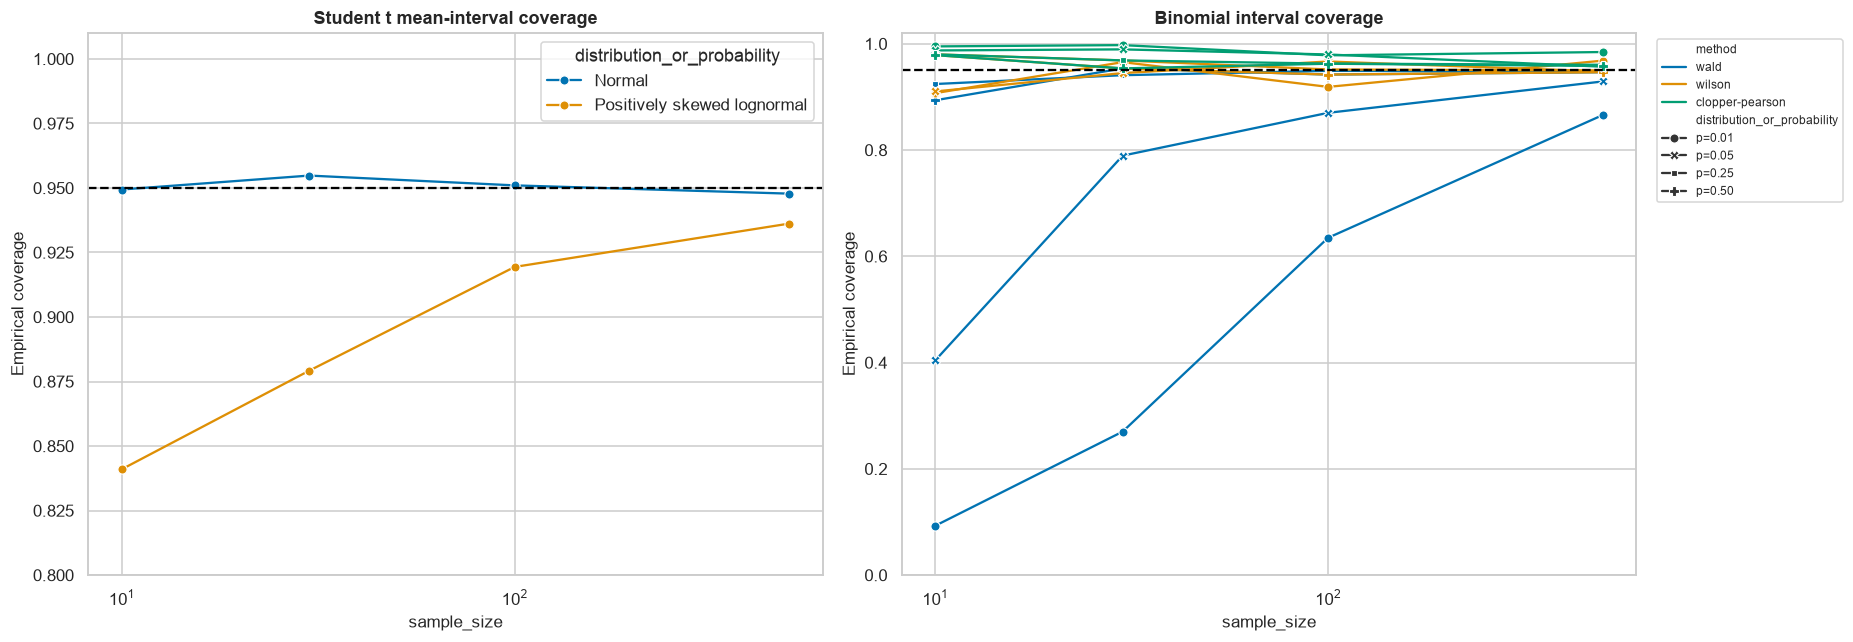

In [14]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
mean_coverage = coverage_simulation[coverage_simulation["family"].eq("mean")]
sns.lineplot(data=mean_coverage, x="sample_size", y="empirical_coverage", hue="distribution_or_probability", marker="o", ax=axes[0])
axes[0].axhline(0.95, color="black", linestyle="--", label="Nominal 95%")
axes[0].set(title="Student t mean-interval coverage", xscale="log", ylim=(0.80, 1.01), ylabel="Empirical coverage")
binomial_coverage = coverage_simulation[coverage_simulation["family"].eq("binomial proportion")]
sns.lineplot(data=binomial_coverage, x="sample_size", y="empirical_coverage", hue="method", style="distribution_or_probability", markers=True, dashes=False, ax=axes[1])
axes[1].axhline(0.95, color="black", linestyle="--")
axes[1].set(title="Binomial interval coverage", xscale="log", ylim=(0, 1.02), ylabel="Empirical coverage")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## 11. Business interpretation and machine-learning implications

Intervals make reliability visible. Overall churn has high support, while narrow segments
and conditional contract–lifecycle cells can have materially wider uncertainty. Onboarding,
month-to-month, electronic-check, fibre-optic, and low support/security adoption estimates
must therefore be interpreted using both magnitude and precision. Monthly-charge exposure
is the share or sum of a billing field associated with observed churners; it is **not**
realized loss, profit, customer lifetime value, or a causal benefit available from an
intervention.

Prioritization should combine observed churn magnitude, interval width, customer population,
financial exposure, intervention cost, operational capacity, and credible evidence that an
action helps. A high point estimate in a tiny group can be less decision-ready than a
moderate, precise rate in a large group. These group intervals are not calibrated individual
churn probabilities and should not be used as such. In ML work, uncertainty motivates
honest validation, subgroup support checks, temporal monitoring, and resampling at the true
independent unit; it does not replace predictive calibration or external validation.

In [15]:
# ruff: noqa: E501
overall_95 = overall_proportion_ci[overall_proportion_ci["confidence_level"].eq(0.95)]
key_segments = segment_ci_table[
    ((segment_ci_table["dimension"].eq("Customer lifecycle")) & segment_ci_table["segment_name"].isin(["0–6: Onboarding", "49–72: Mature"]))
    | ((segment_ci_table["dimension"].eq("Contract")) & segment_ci_table["segment_name"].isin(["Month-to-month", "Two year"]))
    | ((segment_ci_table["dimension"].eq("PaymentMethod")) & segment_ci_table["segment_name"].eq("Electronic check"))
    | ((segment_ci_table["dimension"].eq("InternetService")) & segment_ci_table["segment_name"].isin(["Fiber optic", "DSL"]))
    | ((segment_ci_table["dimension"].eq("Combined support/security adoption")) & segment_ci_table["segment_name"].isin(["Neither security nor support", "Security + support"]))
].sort_values(["dimension", "observed_churn_rate"], ascending=[True, False])
display(Markdown(
    f"### Evidence-aware summary\n\n"
    f"- Overall development churn is **{overall_x / overall_n:.2%}** ({overall_x:,}/{overall_n:,}); the 95% Wilson interval is **{overall_95.loc[overall_95['method'].eq('wilson'), 'lower'].iloc[0]:.2%} to {overall_95.loc[overall_95['method'].eq('wilson'), 'upper'].iloc[0]:.2%}**.\n"
    f"- The churn-associated share of monthly charges is **{point_estimates[estimator_names[7]]:.2%}**. This is exposure, not loss or recoverable value.\n"
    f"- Segment widths range from **{segment_ci_table['interval_width'].min():.2%} to {segment_ci_table['interval_width'].max():.2%}**; sample support changes decision confidence.\n"
    f"- All {len(segment_ci_table)} segment intervals are exploratory and unadjusted for the many displayed comparisons."
))
display(key_segments)

### Evidence-aware summary

- Overall development churn is **26.54%** (1,495/5,634); the 95% Wilson interval is **25.40% to 27.70%**.
- The churn-associated share of monthly charges is **30.39%**. This is exposure, not loss or recoverable value.
- Segment widths range from **1.79% to 18.95%**; sample support changes decision confidence.
- All 45 segment intervals are exploratory and unadjusted for the many displayed comparisons.

,dimension,segment_name,customer_count,churn_count,observed_churn_rate,lower,upper,interval_width,sparse_group,zero_churn_observed,empty_group
25,Combined support/security adoption,Neither security nor support,2050,1003,0.489268,0.467669,0.510907,0.043238,False,False,False
27,Combined support/security adoption,Security + support,875,78,0.089143,0.072014,0.109863,0.037849,False,False,False
0,Contract,Month-to-month,3095,1326,0.428433,0.411098,0.445945,0.034846,False,False,False
2,Contract,Two year,1361,39,0.028655,0.021032,0.038932,0.017900,False,False,False
3,Customer lifecycle,0–6: Onboarding,1191,628,0.527288,0.498892,0.555509,0.056617,False,False,False
7,Customer lifecycle,49–72: Mature,1796,168,0.093541,0.080928,0.107889,0.026961,False,False,False
13,InternetService,Fiber optic,2493,1037,0.415965,0.396761,0.435427,0.038667,False,False,False
12,InternetService,DSL,1934,368,0.190279,0.173406,0.208380,0.034974,False,False,False
10,PaymentMethod,Electronic check,1877,855,0.455514,0.433098,0.478112,0.045014,False,False,False


## 12. Interview questions with speakable answers

### Q1. What is the correct interpretation of a 95% confidence interval?

**Answer:** A frequentist 95% procedure covers the fixed true parameter in about 95% of
repeated samples when its assumptions hold. For the one interval already calculated, the
parameter is not random: the interval either covers it or it does not. The 95% describes
the long-run procedure, not a posterior probability. I would also state the assumed
population, sampling unit, and whether selection or dependence threatens coverage.

### Q2. How do Wald, Wilson, and exact binomial intervals differ?

**Answer:** Wald uses estimate plus or minus a normal standard error. It is symmetric but can
leave zero-to-one bounds, collapse at zero successes, and undercover for small or extreme
samples. Wilson inverts the score statistic, stays within bounds, is asymmetric when needed,
and generally gives better routine coverage. Clopper–Pearson inverts exact binomial tails;
it controls coverage conservatively and is often wider. I prefer Wilson routinely and exact
when conservative finite-sample guarantees are especially important.

### Q3. Bootstrap or analytical confidence interval—which should I use?

**Answer:** Analytical intervals are efficient and transparent when their sampling theory is
credible, such as a large-sample mean interval. Bootstrap intervals are useful for complex
or skewed estimators and preserve row-level dependence when complete rows are resampled.
But the bootstrap inherits source bias and dependence, and BCa may be unstable for tied or
nonsmooth statistics. I compare methods, inspect bias and shape, and justify the resampling
unit instead of assuming bootstrap is automatically superior.

### Q4. Do overlapping 95% confidence intervals imply no statistically meaningful difference?

**Answer:** No. Marginal intervals describe each estimate separately, while a comparison
depends on the sampling distribution and covariance of their difference. Two independent
95% intervals can overlap even when a 95% difference interval excludes zero; paired or
overlapping data change covariance further. I calculate a directly appropriate difference
interval or pre-specified test rather than judging marginal overlap by eye.

## 13. Assumptions, misconceptions, and remaining limitations

1. Customer rows are treated as independent, identically distributed draws; household,
   time, geographic, or account clustering is not available for adjustment.
2. The source sampling mechanism and target telecom population are unknown. All intervals
   are conditional on assumed models and do not fix selection bias.
3. Telecom comparisons were motivated by earlier EDA. They are exploratory and generally
   unadjusted for multiple comparisons; they are not independently confirmatory evidence.
4. Analytical intervals assume their stated sampling approximations. Bootstrap inference
   treats the empirical distribution as a useful stand-in for the unknown source.
5. BCa is limited to smooth estimators with practical, defined jackknife acceleration here;
   tied medians use percentile/basic intervals and are labeled accordingly.
6. Segment zero events do not prove a zero population risk. Empty groups are undefined,
   not zero-risk groups.
7. Association and interval separation do not establish causality, intervention effect,
   fairness, or feature importance.
8. This step stops before formal distribution diagnostics, normality tests, telecom
   hypothesis tests, production preprocessing, feature engineering, or model training.

## 14. Reproducibility, numerical validation, and leakage verification

The last cell validates interval ordering and bounds, comparison directions, deterministic
bootstrap/simulation summaries, configured input, source hash, and all eight prior notebook
hashes. Notebook execution timestamps are volatile metadata; logical reproducibility is
assessed through seeded numerical outputs and invariants rather than byte identity of an
executed notebook.

In [16]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert configured_development_path.name == "development.parquet"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42 and B == 5_000 and R == 5_000
assert (mean_ci_table["lower"] <= mean_ci_table["sample_mean"]).all() and (mean_ci_table["sample_mean"] <= mean_ci_table["upper"]).all()
assert (overall_proportion_ci[overall_proportion_ci["method"].ne("wald")][["lower", "upper"]].to_numpy() >= 0).all()
assert (overall_proportion_ci[overall_proportion_ci["method"].ne("wald")][["lower", "upper"]].to_numpy() <= 1).all()
assert (segment_ci_table[["lower", "observed_churn_rate", "upper"]].diff(axis=1).iloc[:, 1:] >= -1e-12).all().all()
assert (welch_ci_table["lower"] <= welch_ci_table["mean_difference_churned_minus_retained"]).all() and (welch_ci_table["mean_difference_churned_minus_retained"] <= welch_ci_table["upper"]).all()
assert (newcombe_ci_table["lower"] <= newcombe_ci_table["absolute_difference_percentage_points"] / 100).all() and (newcombe_ci_table["absolute_difference_percentage_points"] / 100 <= newcombe_ci_table["upper"]).all()
assert (bootstrap_ci_table["lower"] <= bootstrap_ci_table["upper"]).all()
assert coverage_simulation["empirical_coverage"].between(0, 1).all()
assert coverage_simulation["average_interval_width"].gt(0).all()
assert analysis_df["Customer lifecycle"].notna().all() and analysis_df["Monthly-charge quartile"].notna().all()

repro_rng = np.random.default_rng(random_state)
repro_indices = repro_rng.integers(0, n, size=(10, n))
repro_first = monthly[repro_indices].mean(axis=1)
repro_rng = np.random.default_rng(random_state)
repro_second = monthly[repro_rng.integers(0, n, size=(10, n))].mean(axis=1)
assert np.array_equal(repro_first, repro_second)

print("All confidence-interval, bootstrap, coverage, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All confidence-interval, bootstrap, coverage, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
